In [1]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
proposal_number = 101927227  # noqa
run = 77  # noqa

In [3]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='/jungfrau1M/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    angle='scan/var0'
)

In [4]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None)
valid = xcs.i0_min_max_filter(metadata, 0, 100)

Didn't find the key delay...


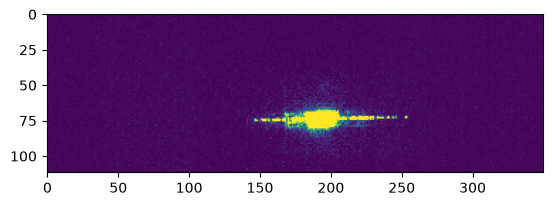

In [5]:
xcs.plot_detector_image(h5, h5dict, samplerate=100).show()

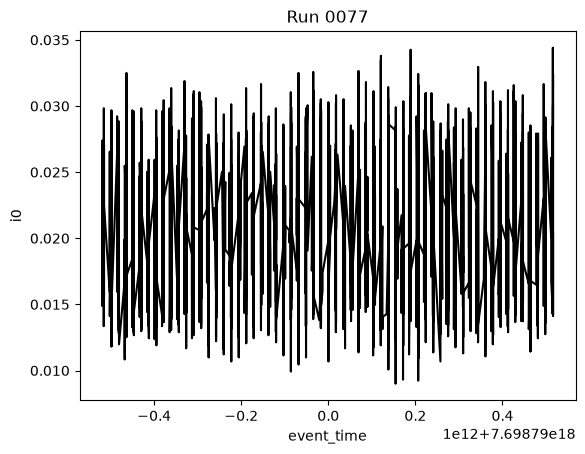

In [6]:
xcs.plot_i0_vs_time(metadata, valid).show()

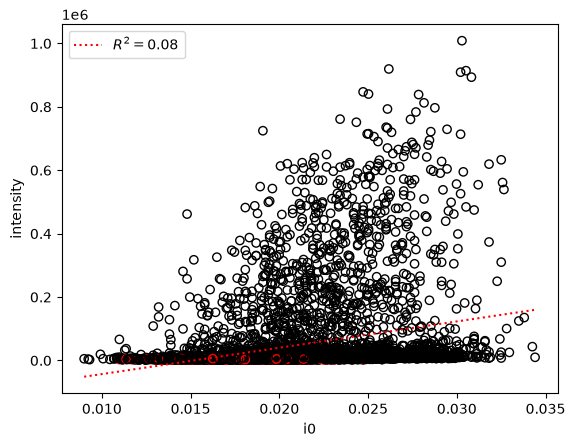

In [7]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

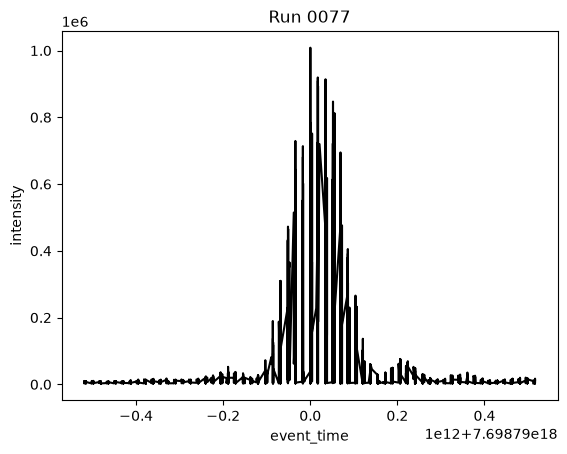

In [8]:
xcs.plot_intensity_vs_time(metadata, valid).show()

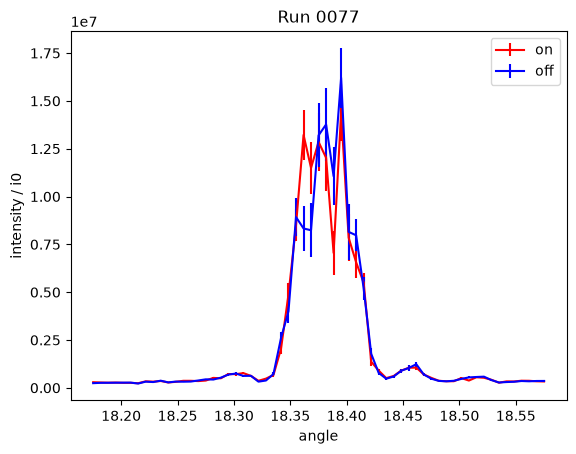

In [9]:
metadata['angle_bin'] = pd.cut(metadata['angle'], 8)
on_metadata = metadata[metadata['laser_on']]
valid_on = valid[metadata['laser_on']]
off_metadata = metadata[~metadata['laser_on']]
valid_off = valid[~metadata['laser_on']]
for meta, color, label, valid_ in zip([on_metadata, off_metadata], ['red', 'blue'], ['on', 'off'], [valid_on, valid_off]):
    rocking = xcs.calc_rocking_stats(h5, h5dict, 'angle', meta, valid_, roi=None)
    plt.errorbar(rocking.index.to_numpy(), rocking['intensity_mean'].to_numpy(), rocking['intensity_stderr'].to_numpy(), color=color, label=label)
    plt.xlabel('angle')
    plt.ylabel('intensity / i0')
plt.title(f'Run {run:04d}')
plt.legend()
plt.show()

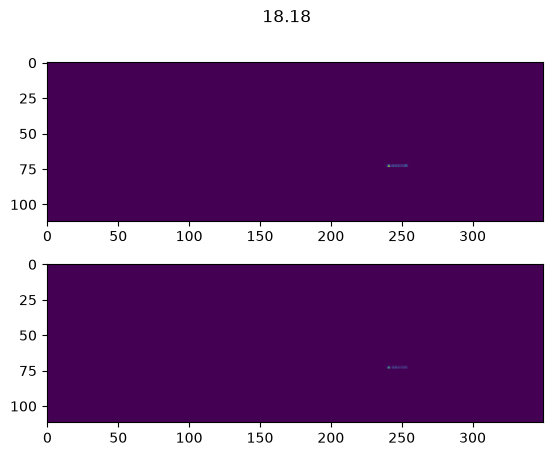

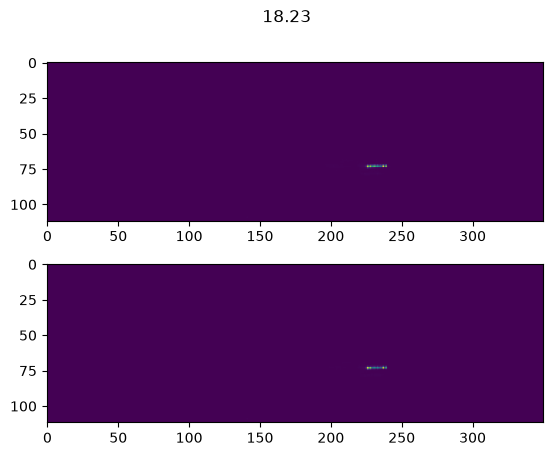

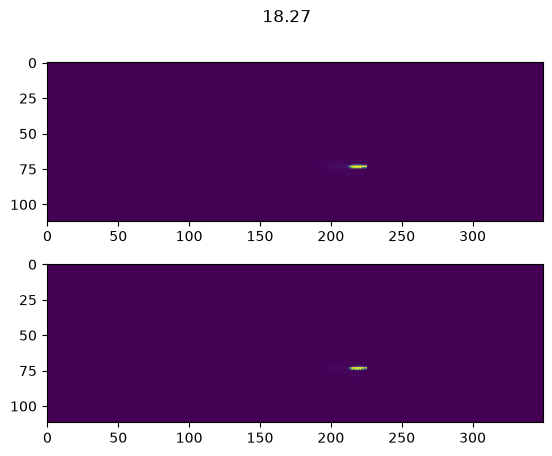

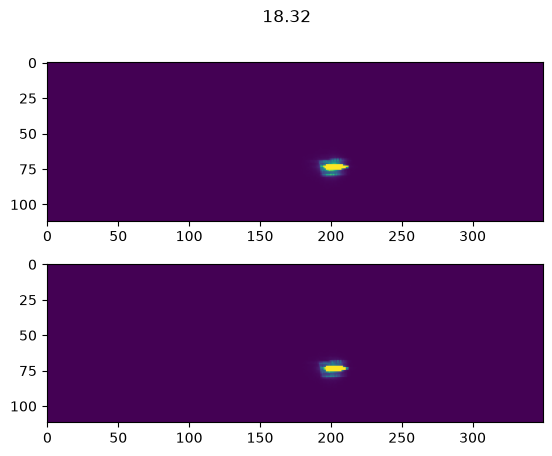

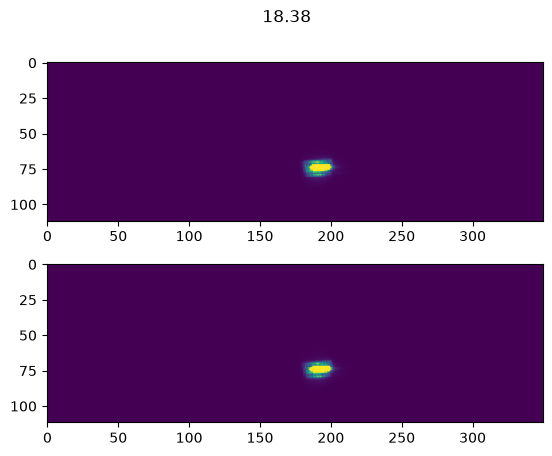

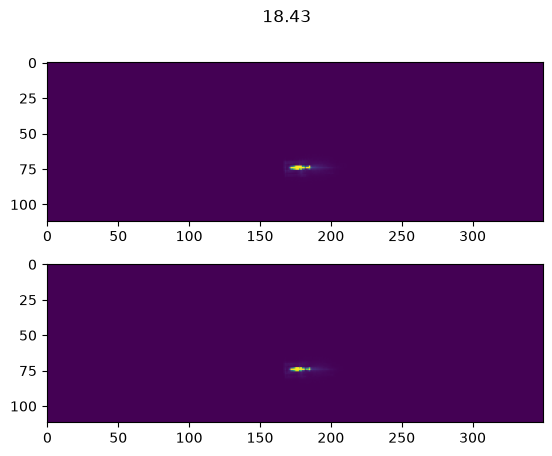

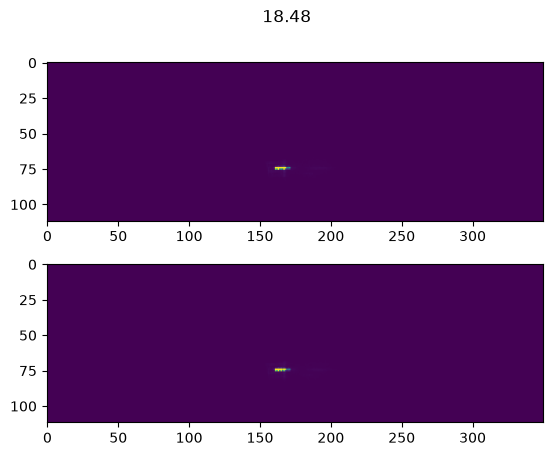

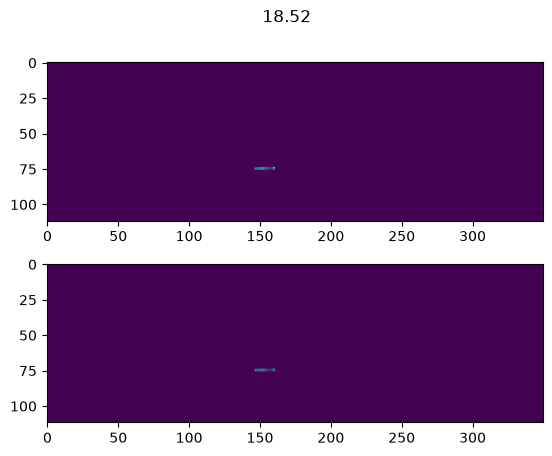

In [10]:
stack = h5[h5dict.stack]
on_ims = []
off_ims = []
for meta, ims in zip([on_metadata, off_metadata], [on_ims, off_ims]):
    for _, group in meta.groupby('angle_bin'):
        shots = group['shot_idx'].to_numpy()
        mean_im = np.mean(stack[shots, ...], axis=0)
        ims.append(mean_im)

on_ims = np.array(on_ims)
off_ims = np.array(off_ims)
vmin = min(np.percentile(on_ims, 0.05), np.percentile(off_ims, 0.05))
vmax = max(np.percentile(on_ims, 99.95), np.percentile(off_ims, 99.95))

for i, (on_im, off_im, angle) in enumerate(zip(on_ims, off_ims, meta['angle_bin'].unique())):
    fig, axs = plt.subplots(2, 1)
    axs[0].imshow(on_im, vmin=vmin, vmax=vmax)
    axs[1].imshow(off_im, vmin=vmin, vmax=vmax)
    fig.suptitle(f'{angle.left:.2f}')
plt.show()